# ORIE 5260 Midterm: Upgrading the Course CTA Strategy

**How to run:** open this notebook in the project folder and use *Kernel → Restart & Run All* (about a minute).
Requirements are in `requirements.txt` (pandas, numpy, matplotlib, openpyxl, pytest).

This notebook is the code walk-through; the design reasoning and the full discussion of results are in the
summary report. Everything is computed from the files in `data/`.

| Section | What it does | Code |
|---|---|---|
| 1 | Rebuild the monthly return panel from daily prices | this notebook |
| 2 | Exploratory data analysis | this notebook |
| 3 | Reproduce the course baseline and static benchmark | `strategies.py`, `engine.py` |
| 4 | Upgrade 1: portfolio vol target (course L6) | `riskmodel.historical_risk` |
| 5 | Upgrade 2: daily EWMA risk model | `daily.py`, `risk.py`, `riskmodel.ewma_risk`, `evaluation.py` |
| 6 | Upgrade 3: risk caps and vol floor | `strategies.VolTargetTSMOM` |
| 7 | Upgrade 4: trend-continuity filter, plus signals we tested and dropped | `trend_strength.py` |
| 8 | Summary: comparison table, alpha vs static, asset classes, crisis alpha | `metrics.py`, `evaluation.py` |
| 9 | Look-ahead tests | `tests/test_lookahead.py` |

All parameters are in `cta_backtest/config.py`. Every strategy goes through the same engine
(`engine.run_backtest`): at each month-end t the strategy only receives returns up to t, and the weights it
returns earn the return of month t+1.

In [1]:
import sys
import subprocess
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
DATA = ROOT / "data"
sys.path.insert(0, str(ROOT))

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
CLASS_COLORS = {"COMM": "#b5651d", "EQ": "#2a78d6", "FI": "#2e8b57", "FX": "#8e44ad"}

## 1. Data

We take the last close of each calendar month and compute `P_t / P_{t-1} - 1` for each of the 62 price files.
Prices are never forward-filled, so a month without a price leaves that month's and the next month's return blank.

Merging follows Lecture 4: ES and SC fold into SP, EN into ND, and RL uses ER's returns from 2008-12 onwards
(RL stops trading then). We splice returns, not price levels. 62 − 4 = 58 columns. The cell below checks
that each merged pair really is the same exposure.

In [2]:
amap = pd.read_csv(DATA / "AssetMapCsv.csv").set_index("ID")
daily_close = {f.stem: pd.read_csv(f, index_col=0, parse_dates=True)["Close"].sort_index()
               for f in sorted((DATA / "FuturesUnderlyingData").glob("*.csv"))}

def monthly_returns(close):
    close = close.dropna()
    month_end = close.groupby(close.index.to_period("M")).last()
    month_end = month_end.reindex(pd.period_range(month_end.index[0], month_end.index[-1], freq="M"))
    return month_end.pct_change(fill_method=None)

raw_monthly = pd.DataFrame({k: monthly_returns(v) for k, v in daily_close.items()})
print(len(daily_close), "price files; in the asset map without a file:", sorted(set(amap.index) - set(daily_close)))

pairs = [("SP", "ES"), ("SP", "SC"), ("ND", "EN"), ("RL", "ER")]
pd.DataFrame([{"keep": a, "merge": b, "overlap months": len(raw_monthly[[a, b]].dropna()),
               "correlation": raw_monthly[a].corr(raw_monthly[b])} for a, b in pairs])

62 price files; in the asset map without a file: ['BC', 'BG', 'FF', 'ZH']


,keep,merge,overlap months,correlation
0,SP,ES,207,1.000
1,SP,SC,249,1.000
2,ND,EN,186,1.000
3,RL,ER,73,0.994


In [3]:
reference = pd.read_csv(DATA / "MonthlyReturns.csv", index_col=0)      # course file, used for checking only
months = pd.to_datetime(reference.index).to_period("M")

panel = raw_monthly.reindex(index=months, columns=reference.columns)
after = months >= pd.Period("2008-12", "M")
panel.loc[after, "RL"] = raw_monthly["ER"].reindex(months[after]).values

ref = reference.set_axis(months)
both = ref.notna() & panel.notna()
print("max |difference| vs course file:", float((panel - ref)[both].abs().max().max()))
print("values blank in the course file but available from prices:", int((ref.isna() & panel.notna()).sum().sum()))

# This file is the only return input of the backtest (cta_backtest/config.py -> returns_path)
panel.set_axis(reference.index).to_csv(ROOT / "MonthlyReturns.csv", encoding="utf-8-sig")
returns = panel.set_axis(months.to_timestamp("M"))
asset_class = amap["AssetClass"].reindex(returns.columns)
asset_class["EC"] = "FI"      # Eurodollar is a USD short-rate future; the asset map labels it FX
print(returns.shape, returns.index[0].date(), "to", returns.index[-1].date())

max |difference| vs course file: 4.6592380423040865e-08
values blank in the course file but available from prices: 32
(552, 58) 1969-01-31 to 2014-12-31


The rebuilt panel matches the course file wherever the course file has a value. We keep the 32 extra values
(both month-end prices exist).

**Outliers.** We flag daily moves above 15% and monthly moves above 30%. Each flagged day matches a known market
event (e.g. 19 Oct 1987, 17 Jan 1991, 3 Jan 2001), so we keep all values unchanged.

In [4]:
flags = []
for k, close in daily_close.items():
    r = close.pct_change(fill_method=None)
    for d in r.index[r.abs() > 0.15]:
        flags.append({"ID": k, "name": amap.Name.get(k), "date": d.date(), "daily return": r[d]})
flags = pd.DataFrame(flags).sort_values("date").reset_index(drop=True)
big_months = returns.stack()[lambda s: s.abs() > 0.30]
print(len(flags), "daily moves > 15%;", len(big_months), "monthly moves > 30%, by class:",
      big_months.groupby(asset_class.reindex(big_months.index.get_level_values(1)).values).size().to_dict())
flags

31 daily moves > 15%; 105 monthly moves > 30%, by class: {'COMM': 104, 'EQ': 1}


,ID,name,date,daily return
0,ZM,SoybeanMeal,1973-06-11,0.175
1,ZS,Soybeans,1973-06-22,-0.161
2,ZL,SoybeanOil,1973-08-22,0.216
3,SB,Sugar,1983-06-01,-0.165
4,SB,Sugar,1985-07-26,0.153
5,ZU,CrudeOil,1986-08-04,0.151
6,SP,SP500,1987-10-19,-0.286
7,SP,SP500,1987-10-21,0.194
8,SB,Sugar,1988-07-26,-0.167
9,ZU,CrudeOil,1991-01-17,-0.319


## 2. Exploratory data analysis

Per-instrument statistics on each instrument's own history (long only, monthly returns annualised),
then averaged by asset class. The full per-instrument table is `ann`.

In [5]:
ann = pd.DataFrame({
    "class": asset_class,
    "first": returns.apply(lambda s: s.first_valid_index().year),
    "mean": returns.mean() * 12,
    "vol": returns.std() * np.sqrt(12),
    "skew": returns.skew(),
    "excess kurt": returns.kurt(),
})
ann["sharpe"] = ann["mean"] / ann["vol"]

ann.groupby("class").agg(
    instruments=("mean", "size"), first_year=("first", "min"),
    mean=("mean", "mean"), vol_median=("vol", "median"), vol_min=("vol", "min"), vol_max=("vol", "max"),
    sharpe=("sharpe", "mean"), excess_kurt=("excess kurt", "median"))

,instruments,first_year,mean,vol_median,vol_min,vol_max,sharpe,excess_kurt
class,,,,,,,,
COMM,26,1969,0.035,0.291,0.147,0.513,0.130,3.343
EQ,14,1982,0.055,0.176,0.141,0.271,0.299,1.306
FI,11,1978,0.028,0.042,0.011,0.113,0.673,0.699
FX,7,1975,0.017,0.112,0.068,0.123,0.159,1.807


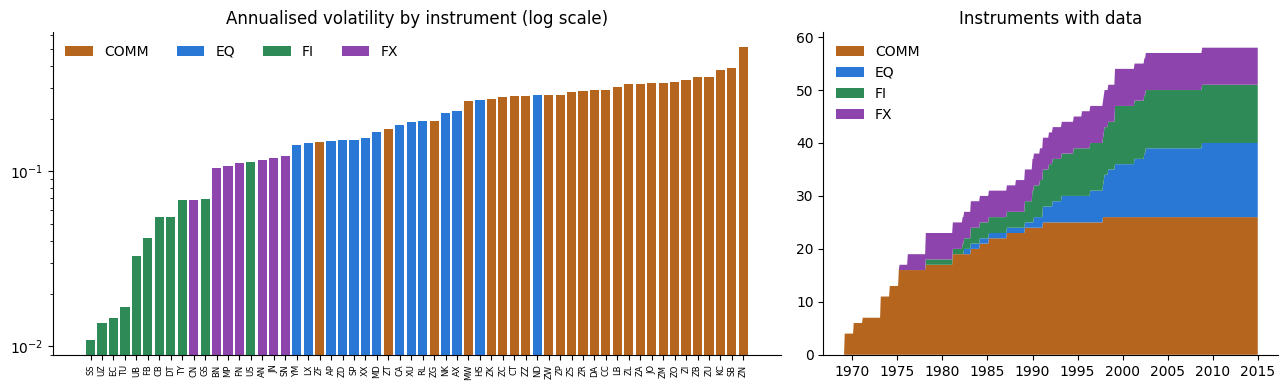

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.6, 1]})
s = ann.sort_values("vol")
a1.bar(s.index, s["vol"], color=s["class"].map(CLASS_COLORS))
a1.set_yscale("log"); a1.set_title("Annualised volatility by instrument (log scale)")
a1.tick_params(axis="x", labelsize=6, rotation=90)
for c, col in CLASS_COLORS.items():
    a1.bar(0, 0, color=col, label=c)
a1.legend(frameon=False, ncol=4)

counts = returns.notna().T.groupby(asset_class).sum().T
a2.stackplot(counts.index, [counts[c] for c in CLASS_COLORS], colors=CLASS_COLORS.values(), labels=CLASS_COLORS)
a2.set_title("Instruments with data"); a2.legend(frameon=False, loc="upper left")
plt.tight_layout()

Cumulative long-only returns by asset class. To make classes comparable, each instrument is scaled to 10% vol
with its full-sample std. This is for description only; the strategies never use full-sample statistics.

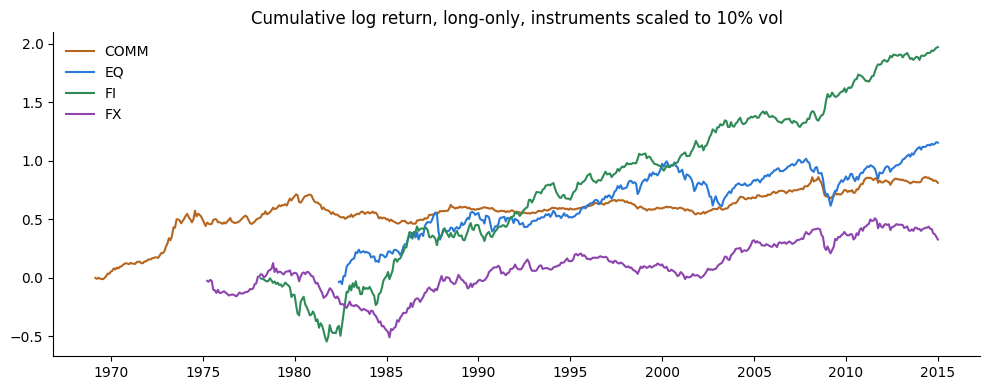

In [7]:
scaled = returns / (returns.std() * np.sqrt(12)) * 0.10
class_ret = scaled.T.groupby(asset_class).mean().T

fig, ax = plt.subplots()
for c in CLASS_COLORS:
    r = class_ret[c].dropna()
    ax.plot(np.log((1 + r).cumprod()), color=CLASS_COLORS[c], label=c)
ax.set_title("Cumulative log return, long-only, instruments scaled to 10% vol"); ax.legend(frameon=False)
plt.tight_layout()

**Autocorrelation across horizons.** We pool all instruments (each divided by its std so that each counts
equally) and compute (left) the autocorrelation at lag k and (right) the correlation of next month's return
with the past k-month return, which is what a k-month TSMOM signal uses. The red lines are ±2/√N.
These pooled bands ignore cross-instrument correlation, so read them as a rough guide.

past months,1,3,6,12,24,36
COMM,0.035,0.042,0.045,0.051,0.011,0.007
EQ,0.073,0.045,0.041,0.044,0.005,-0.018
FI,0.106,0.069,0.022,0.049,0.006,-0.001
FX,0.031,0.076,0.030,0.058,0.050,0.031
all,0.054,0.056,0.046,0.060,0.029,0.022


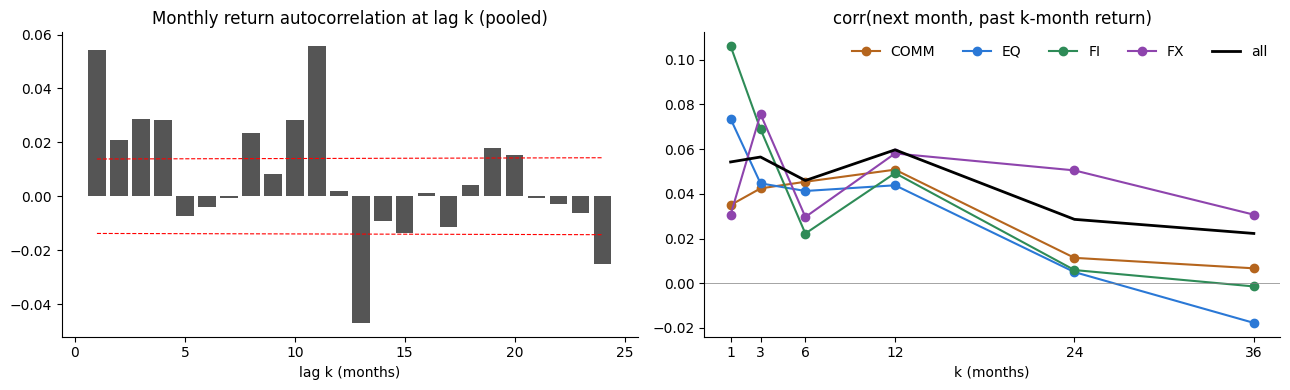

In [8]:
z = returns / returns.std()

def pooled_corr(x, y):
    xy = pd.concat([x.stack(), y.stack()], axis=1).dropna()
    return xy.corr().iloc[0, 1], len(xy)

lags = range(1, 25)
acf = pd.DataFrame([pooled_corr(z, z.shift(k)) for k in lags], index=lags, columns=["corr", "n"])

horizons = [1, 3, 6, 12, 24, 36]
pred = pd.DataFrame({c: [pooled_corr(z.loc[:, asset_class == c].shift(-1),
                                     z.loc[:, asset_class == c].rolling(k).sum())[0] for k in horizons]
                     for c in CLASS_COLORS}, index=horizons)
pred["all"] = [pooled_corr(z.shift(-1), z.rolling(k).sum())[0] for k in horizons]
pred.index.name = "past months"

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
band = 2 / np.sqrt(acf["n"])
a1.bar(acf.index, acf["corr"], color="#555")
a1.plot(acf.index, band, "r--", lw=0.8); a1.plot(acf.index, -band, "r--", lw=0.8)
a1.set(title="Monthly return autocorrelation at lag k (pooled)", xlabel="lag k (months)")
for c in CLASS_COLORS:
    a2.plot(pred.index, pred[c], "o-", color=CLASS_COLORS[c], label=c)
a2.plot(pred.index, pred["all"], "k-", lw=2, label="all")
a2.axhline(0, color="grey", lw=0.5)
a2.set(title="corr(next month, past k-month return)", xlabel="k (months)", xticks=horizons)
a2.legend(frameon=False, ncol=5)
plt.tight_layout()
pred.T

In [9]:
# The 12-month predictor before and after our train/test split (end of 1999)
past12 = z.rolling(12).sum()
pd.Series({"1969-1999": pooled_corr(z.shift(-1).loc[:"1999"], past12.loc[:"1999"])[0],
           "2000-2014": pooled_corr(z.shift(-1).loc["2000":], past12.loc["2000":])[0]},
          name="corr(next month, past 12m)")

1969-1999    0.077
2000-2014    0.039
Name: corr(next month, past 12m), dtype: float64

## 3. Course baseline and static benchmark

From here on everything uses the `cta_backtest` package. `load_market_data` reads the panel saved in section 1
and the asset map. The two course strategies are in `strategies.py`:

* `TSMOMBaseline`: `w_i = sign(sum of last 12 monthly returns) × 40% / σ_i / N`, σ_i = expanding vol
  (needs 36 months), trades only when N ≥ 10.
* `StaticBenchmark`: same instruments and sizing, always long.

We also run the 1-, 3- and 6-month lookbacks and compare with the Lecture 6 table.

In [10]:
from cta_backtest import (BacktestConfig, StaticBenchmark, TSMOMBaseline, VolTargetTSMOM,
                          ewma_risk, historical_risk, load_market_data, metrics, run_backtest)
from cta_backtest.daily import load_daily_returns
from cta_backtest.trend_strength import continuity_monthly
from cta_backtest import evaluation as ev

cfg = BacktestConfig()
md = load_market_data(cfg)
m = md.returns

def sr(x):
    return x.mean() / x.std() * np.sqrt(12)

results = {"STATIC": run_backtest(m, StaticBenchmark(cfg), "STATIC")}
for lb in (1, 3, 6, 12):
    results[f"TSMOM_{lb}"] = run_backtest(m, TSMOMBaseline(replace(cfg, momentum_lookback=lb)), f"TSMOM_{lb}")

lecture6 = pd.DataFrame({"TSMOM_12": (0.111, 0.111, 1.00, 0.08), "TSMOM_6": (0.090, 0.114, 0.79, -0.01),
                         "TSMOM_3": (0.096, 0.118, 0.81, -0.09), "TSMOM_1": (0.081, 0.112, 0.72, -0.11),
                         "STATIC": (0.069, 0.145, 0.47, 1.00)},
                        index=["L6 avg", "L6 std", "L6 SR", "L6 corr"]).T
static = results["STATIC"].returns
ours = pd.DataFrame({k: {"avg": r.returns.mean() * 12, "std": r.returns.std() * np.sqrt(12),
                         "SR": sr(r.returns), "corr w/ static": r.returns.corr(static)}
                     for k, r in results.items()}).T
ours.join(lecture6).loc[["TSMOM_12", "TSMOM_6", "TSMOM_3", "TSMOM_1", "STATIC"]]

,avg,std,SR,corr w/ static,L6 avg,L6 std,L6 SR,L6 corr
TSMOM_12,0.110,0.111,0.992,0.079,0.111,0.111,1.00,0.08
TSMOM_6,0.089,0.114,0.785,-0.006,0.090,0.114,0.79,-0.01
TSMOM_3,0.095,0.118,0.805,-0.093,0.096,0.118,0.81,-0.09
TSMOM_1,0.080,0.113,0.711,-0.111,0.081,0.112,0.72,-0.11
STATIC,0.069,0.145,0.477,1.000,0.069,0.145,0.47,1.00


Our numbers match Lecture 6. Getting there needed one detail: the course signal is the **sum** of the last
12 monthly returns, not the compounded return (`config.momentum_aggregation = "sum"`).

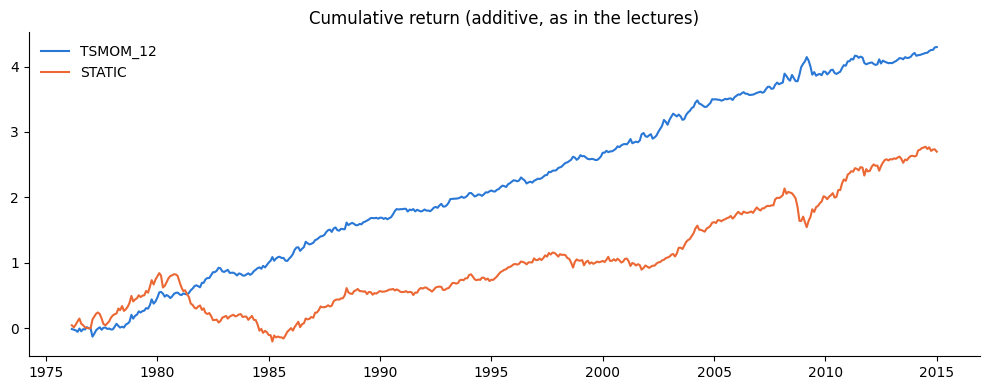

In [11]:
fig, ax = plt.subplots()
for k, c in [("TSMOM_12", "#2a78d6"), ("STATIC", "#eb6834")]:
    ax.plot(results[k].returns.cumsum(), color=c, label=k)
ax.set_title("Cumulative return (additive, as in the lectures)"); ax.legend(frameon=False)
plt.tight_layout()

## 4. Upgrade 1: portfolio vol target

`historical_risk` (in `riskmodel.py`) is the Lecture 6 risk model: expanding-window covariance of monthly
returns, re-estimated every month with data up to that month. It returns a `RiskModel` object, and
`risk.at(t)` gives the vols and covariance known at t.

`VolTargetTSMOM(cfg, risk, sizing="baseline")` keeps the course positions and rescales the whole book so that
its forecast vol `sqrt(w'Σw)` is 11% every month (`config.portfolio_vol_target`).

In [12]:
H = historical_risk(m, cfg)
results["VT11_historical"] = run_backtest(m, VolTargetTSMOM(cfg, H, "baseline"), "VT11_historical")

## 5. Upgrade 2: daily EWMA risk model

`load_daily_returns` (`daily.py`) builds close-to-close daily returns for the 58 columns, applying the same
RL → ER switch as the monthly panel. A return spanning more than 7 calendar days is dropped as a data gap.

`ewma_risk` (`riskmodel.py`) builds the model in three pieces, all in `risk.py`:

* `ewma_volatility_monthly`: EWMA of squared daily returns, read on the last trading day of each month.
* `ewma_correlation_monthly`: EWMA correlation of overlapping 3-day returns (3-day sums absorb the different
  closing times across time zones). The result is projected to a valid correlation matrix.
* covariance `Σ = D C D`, with D the EWMA vols.

**Choosing the half-lives.** `evaluation.py` scores each candidate on the next month's realised return.
The choice uses QLIKE on data up to 1999 only (lower is better); bias (ideal 1) and MRAD are shown as checks.

In [13]:
daily = load_daily_returns(cfg.daily_dir, m.columns, cfg.daily_splices, cfg.daily_max_gap_days)

vol_scores, vol_bias_by_year = ev.score_vol_halflives(m, daily, cfg)
vol_scores.pivot(index="model", columns="sample", values=["qlike_monthly", "bias", "mrad"]).loc[vol_scores.model.unique()]

qlike_monthly          bias          mrad       
sample                      test  train   test  train   test  train
model                                                              
expanding (course)        -2.745 -2.234  0.980  0.953  0.331  0.355
EWMA 10d                  -2.892 -2.304  1.104  1.223  0.220  0.266
EWMA 20d                  -2.911 -2.353  1.069  1.179  0.218  0.249
EWMA 40d                  -2.912 -2.372  1.042  1.150  0.228  0.249
EWMA 60d                  -2.905 -2.374  1.028  1.137  0.238  0.257
EWMA 90d                  -2.893 -2.369  1.014  1.129  0.250  0.266

EWMA beats the expanding estimate on every measure. 60 days has the lowest training QLIKE, with 40–90 days
almost identical, so the choice is not sensitive (`config.vol_halflife_days = 60`).
The chart shows the bias statistic by year: the course estimate drifts far from 1 in calm and stressed
years, the EWMA stays close.

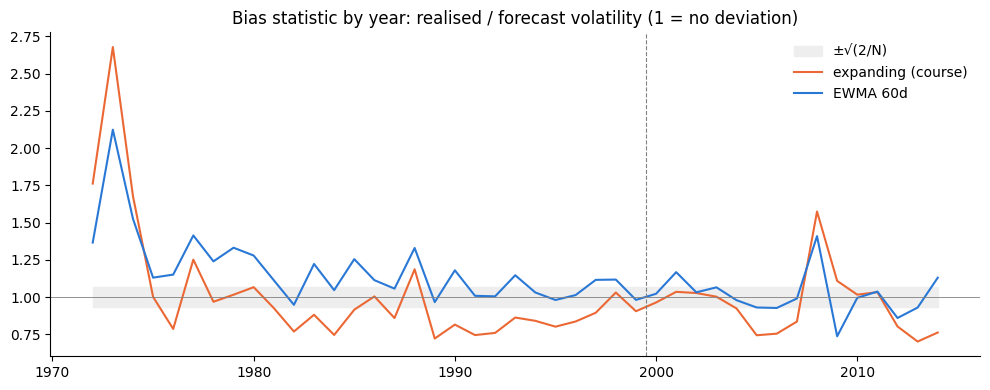

In [14]:
n_year = vol_scores.query("model == 'EWMA 60d'")["n"].sum() / len(vol_bias_by_year)
fig, ax = plt.subplots()
ax.fill_between(vol_bias_by_year.index, 1 - np.sqrt(2 / n_year), 1 + np.sqrt(2 / n_year), color="#eee", label="±√(2/N)")
ax.plot(vol_bias_by_year["expanding (course)"], color="#eb6834", label="expanding (course)")
ax.plot(vol_bias_by_year["EWMA 60d"], color="#2a78d6", label="EWMA 60d")
ax.axhline(1, color="grey", lw=0.6); ax.axvline(1999.5, color="grey", ls="--", lw=0.8)
ax.set_title("Bias statistic by year: realised / forecast volatility (1 = no deviation)"); ax.legend(frameon=False)
plt.tight_layout()

For the covariance, a forecast only matters through portfolios, so `score_covariance_models` scores each model
on four kinds of portfolios formed at t and held over t+1: the course TSMOM book, the static book, one long book
per asset class, and 50 random long/short books. The ranking averages training QLIKE over the four groups.

In [15]:
cov_scores = ev.score_covariance_models(m, daily, md.asset_class, cfg)
ranking = cov_scores.query("sample == 'train'").groupby("model")["qlike_monthly"].mean().sort_values()
bias = cov_scores.pivot_table(index="model", columns=["sample", "group"], values="bias")
bias.loc[ranking.index].assign(train_qlike_avg=ranking)

sample                  test                       train                       \
group                  CLASS RANDOM STATIC  TSMOM  CLASS RANDOM STATIC  TSMOM   
model                                                                           
EWMA corr 120d, 3-day  1.044  1.046  1.069  0.977  1.077  1.161  1.095  1.104   
EWMA corr 250d, 3-day  1.045  1.044  1.061  1.012  1.076  1.158  1.087  1.127   
EWMA corr 60d, 3-day   1.047  1.051  1.083  0.952  1.080  1.167  1.102  1.092   
EWMA corr 500d, 3-day  1.059  1.042  1.072  1.043  1.078  1.156  1.079  1.149   
EWMA corr 120d, 1-day  1.065  1.042  1.119  1.049  1.083  1.159  1.101  1.144   
EWMA corr 60d, 1-day   1.068  1.046  1.130  1.028  1.087  1.162  1.105  1.135   
EWMA corr 250d, 1-day  1.068  1.041  1.113  1.074  1.081  1.157  1.094  1.159   
EWMA corr 500d, 1-day  1.081  1.039  1.124  1.097  1.083  1.156  1.086  1.174   
expanding (course)     1.029  0.823  1.181  1.133  0.825  0.814  0.834  0.907   
EWMA vol, zero corr    2.406  1.037  2.712  2.214  1.949  1.149  2.126  1.545   

sample                train_qlike_avg  
group                                  
model                                  
EWMA corr 120d, 3-day          -2.072  
EWMA corr 250d, 3-day          -2.071  
EWMA corr 60d, 3-day           -2.068  
EWMA corr 500d, 3-day          -2.065  
EWMA corr 120d, 1-day          -2.065  
EWMA corr 60d, 1-day           -2.064  
EWMA corr 250d, 1-day          -2.063  
EWMA corr 500d, 1-day          -2.058  
expanding (course)             -2.033  
EWMA vol, zero corr            -1.031

EWMA correlation with a 120-day half-life on 3-day returns ranks first (`corr_halflife_days = 120`,
`corr_overlap_days = 3`). The "zero corr" row shows what ignoring correlation does: the TSMOM and static books'
risk would be understated by about half (bias ≈ 2).

In [16]:
E = ewma_risk(daily, m, cfg)
results["VT11_ewma"] = run_backtest(m, VolTargetTSMOM(cfg, E, "baseline"), "VT11_ewma")

## 6. Upgrade 3: risk caps and vol floor

`sizing="capped"` changes position sizing inside `VolTargetTSMOM`:

1. every position starts at unit risk, `sign / σ`;
2. `_apply_caps` limits each instrument to 10% and each asset class to 40% of the book's standalone risk,
   using `soft_cap_shares`: `share = cap × tanh(λ × raw / cap)`, λ solved so the shares sum to 1;
3. the book is scaled to 11% as before.

The vol floor is part of `ewma_risk`: the EWMA vol is never below 50% of the instrument's own historical vol
to date (`config.vol_floor_vs_history`). The cell below shows what the floor and the caps change.

In [17]:
results["CTA_v1"] = run_backtest(m, VolTargetTSMOM(cfg, E, "capped", md.asset_class), "CTA_v1")

E_nofloor = ewma_risk(daily, m, replace(cfg, vol_floor_vs_history=0.0))
nofloor = run_backtest(m, VolTargetTSMOM(cfg, E_nofloor, "capped", md.asset_class), "no floor")
pd.DataFrame({k: {"peak gross leverage": r.held_weights.abs().sum(axis=1).max(),
                  "largest single position": r.held_weights.abs().max().max(), "SR": sr(r.returns)}
              for k, r in {"without floor": nofloor, "with floor (CTA_v1)": results["CTA_v1"]}.items()})

,without floor,with floor (CTA_v1)
peak gross leverage,31.489,12.485
largest single position,17.208,2.659
SR,1.298,1.285


,COMM,EQ,FI,FX
without caps,0.448,0.168,0.201,0.184
with caps,0.377,0.169,0.222,0.232


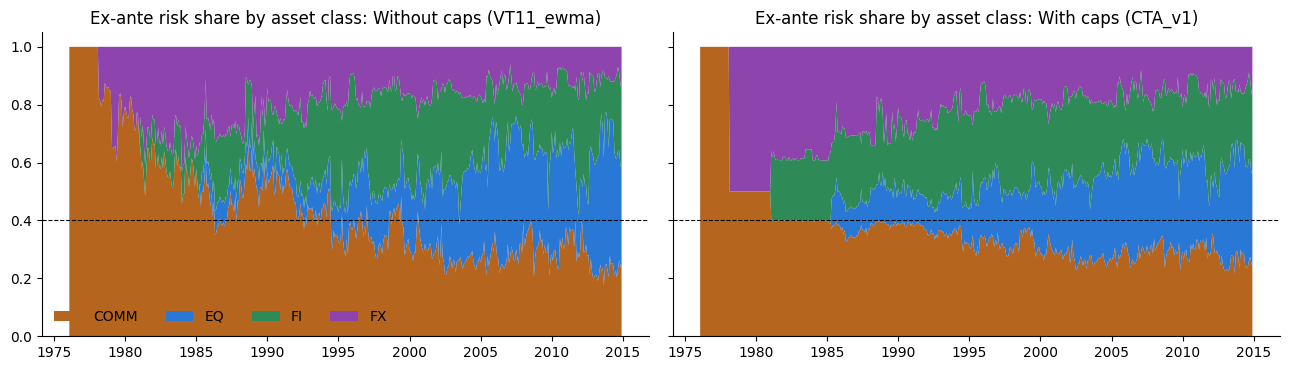

In [18]:
share_nocap = ev.class_risk_shares(results["VT11_ewma"].weights, E, md.asset_class)
share_cap = ev.class_risk_shares(results["CTA_v1"].weights, E, md.asset_class)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, sh, title in [(axes[0], share_nocap, "Without caps (VT11_ewma)"), (axes[1], share_cap, "With caps (CTA_v1)")]:
    ax.stackplot(sh.index, [sh[c] for c in CLASS_COLORS], colors=CLASS_COLORS.values(), labels=CLASS_COLORS)
    ax.axhline(0.4, color="k", ls="--", lw=0.8)
    ax.set_title(f"Ex-ante risk share by asset class: {title}")
axes[0].legend(frameon=False, loc="lower left", ncol=4)
plt.tight_layout()
pd.DataFrame({"without caps": share_nocap.mean(), "with caps": share_cap.mean()}).T

The caps bind mainly before about 1992, when most tradable markets were commodities. In the late 1970s only
one or two classes trade, so a 40% class cap cannot be met; `soft_cap_shares` then gives equal shares.

## 7. Upgrade 4: trend-continuity filter

`continuity_monthly` (`trend_strength.py`) computes, for each instrument and month,
`sign(past 12m return) × (share of up days − share of down days)` over the last 252 trading days.

We first check on data to 1999 whether it predicts the payoff of the TSMOM position. Each month we sort
instruments into five groups by continuity and average the next-month payoff per unit of risk,
`sign_t × r_{t+1} / σ_t`.

In [19]:
cont = continuity_monthly(daily, m, cfg.momentum_lookback, cfg.continuity_window_days)

per = m.set_axis(m.index.to_period("M"))
sign12 = np.sign(per.rolling(12, min_periods=12).sum())
vol_m = pd.DataFrame(E.vol, index=per.index, columns=m.columns) / np.sqrt(12)
payoff = (sign12 * per.shift(-1) / vol_m).stack().rename("payoff")

q = pd.concat([payoff, cont.stack().rename("continuity")], axis=1).dropna()
q = q[(q.index.get_level_values(0) + 1 <= pd.Period(cfg.risk_train_end, "M")) & (q["payoff"] != 0)]
q["group"] = q.groupby(level=0)["continuity"].transform(lambda x: pd.qcut(x.rank(method="first"), 5, labels=False) + 1)
by_month = q.groupby([q.index.get_level_values(0), "group"])["payoff"].mean().unstack()
spread = (by_month[5] - by_month[1]).dropna()
print(f"Q5 - Q1 = {spread.mean():.3f} per month, t = {spread.mean() / spread.std() * np.sqrt(len(spread)):.2f}")
by_month.mean().rename("mean payoff (Q1 = jumpiest, Q5 = steadiest)").to_frame().T

Q5 - Q1 = 0.140 per month, t = 2.59


group,1,2,3,4,5
"mean payoff (Q1 = jumpiest, Q5 = steadiest)",0.101,0.113,0.129,0.176,0.241


The steadiest trends pay more than twice as much as the jumpiest. The rule, chosen on data to 1999:
each month rank instruments by continuity; positions below the median get half weight
(`strength_panel` argument of `VolTargetTSMOM`). The direction is still sign(12m).

In [20]:
results["CTA_v2"] = run_backtest(m, VolTargetTSMOM(cfg, E, "capped", md.asset_class,
                                                   strength_panel=cont.rank(axis=1, pct=True),
                                                   strength_threshold=0.5,
                                                   strength_low_weight=cfg.continuity_low_weight), "CTA_v2")

**Signals we tested and dropped.** Each alternative replaces sign(12m) through the `signal_panel` argument,
on the same CTA_v1 engine (same risk model, caps, vol target and universe):

* multi-horizon: average of sign(1m), sign(3m), sign(12m);
* continuous: past 12m return divided by its standard error (no sign, size grows with the t-stat);
* risk-adjusted 12m: each monthly return divided by its vol forecast before taking the 12m sum.

In [21]:
alternatives = {
    "sign(12m) = CTA_v1": None,
    "multi-horizon 1/3/12m": ev.sign_panel(m, [1, 3, 12]),
    "continuous (t-stat)": ev.tstat_panel(m, E.vol, 12),
    "risk-adjusted 12m": ev.sign_panel(m, [12], E.vol),
}
rows = {}
for name, panel_ in alternatives.items():
    r = run_backtest(m, VolTargetTSMOM(cfg, E, "capped", md.asset_class, signal_panel=panel_), name)
    x = r.returns
    rows[name] = {"SR to 1999": sr(x[:"1999"]), "SR from 2000": sr(x["2000":]),
                  "max drawdown": metrics.drawdown(x).min(), "turnover / yr": r.turnover.iloc[1:].mean() * 12}
pd.DataFrame(rows).T

,SR to 1999,SR from 2000,max drawdown,turnover / yr
sign(12m) = CTA_v1,1.359,1.161,-0.139,18.341
multi-horizon 1/3/12m,1.459,1.128,-0.171,42.312
continuous (t-stat),1.253,1.207,-0.210,15.975
risk-adjusted 12m,1.374,1.189,-0.128,17.570


## 8. Summary

All versions trade the same instruments in the same months (same eligibility rule), so the rows are directly
comparable. Training sample: to 1999. Test sample: 2000–2014. Returns are before transaction costs.

In [22]:
LADDER = ["TSMOM_12", "VT11_historical", "VT11_ewma", "CTA_v1", "CTA_v2"]
LABEL = {"TSMOM_12": "Course baseline", "VT11_historical": "+ vol target (course L6)",
         "VT11_ewma": "+ daily EWMA risk model", "CTA_v1": "+ risk caps and vol floor",
         "CTA_v2": "+ trend-continuity filter"}
assert len({tuple(results[k].returns.index) for k in LADDER + ["STATIC"]}) == 1

summary = pd.DataFrame({LABEL[k]: {
    "SR": sr(x), "SR to 1999": sr(x[:"1999"]), "SR from 2000": sr(x["2000":]),
    "return": x.mean() * 12, "vol": x.std() * np.sqrt(12), "max drawdown": metrics.drawdown(x).min(),
    "skew": x.skew(), "corr w/ static": x.corr(static),
    "turnover / yr": results[k].turnover.iloc[1:].mean() * 12,
    "avg gross": results[k].held_weights.abs().sum(axis=1).mean()}
    for k in LADDER for x in [results[k].returns]}).T
summary

,SR,SR to 1999,SR from 2000,return,vol,max drawdown,skew,corr w/ static,turnover / yr,avg gross
Course baseline,0.992,1.127,0.839,0.110,0.111,-0.260,-0.071,0.079,8.549,3.214
+ vol target (course L6),1.071,1.171,0.959,0.119,0.111,-0.192,-0.156,0.097,11.845,3.502
+ daily EWMA risk model,1.276,1.334,1.177,0.148,0.116,-0.146,-0.069,0.140,15.599,4.405
+ risk caps and vol floor,1.285,1.359,1.161,0.149,0.116,-0.139,-0.129,0.115,18.341,4.780
+ trend-continuity filter,1.340,1.439,1.172,0.156,0.116,-0.120,-0.061,0.143,17.386,4.443


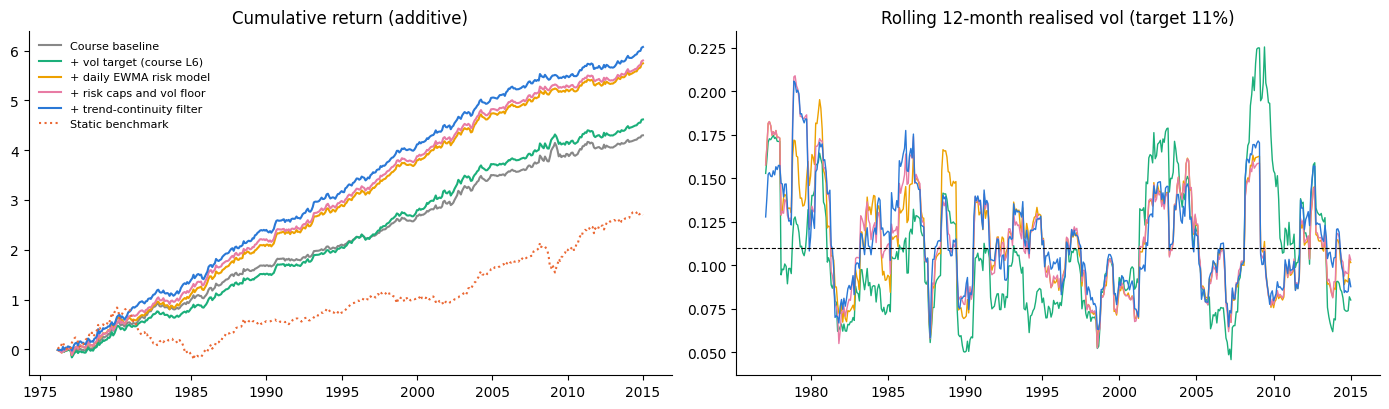

In [23]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.2))
colors = ["#888", "#1baf7a", "#eda100", "#e87ba4", "#2a78d6"]
for k, c in zip(LADDER, colors):
    a1.plot(results[k].returns.cumsum(), color=c, label=LABEL[k])
    if k != "TSMOM_12":
        a2.plot(results[k].returns.rolling(12).std() * np.sqrt(12), color=c, lw=1)
a1.plot(static.cumsum(), color="#eb6834", ls=":", label="Static benchmark")
a1.set_title("Cumulative return (additive)"); a1.legend(frameon=False, fontsize=8)
a2.axhline(0.11, color="k", ls="--", lw=0.8)
a2.set_title("Rolling 12-month realised vol (target 11%)")
plt.tight_layout()

**Alpha against the static benchmark** (course L4/L6): `r = α + β × r_static`.

In [24]:
pd.DataFrame({LABEL[k]: ev.ols(results[k].returns, static.to_frame("static")) for k in LADDER}).T

,alpha (ann.),t(alpha),beta static,t(static),R2
Course baseline,0.106,5.906,0.061,1.720,0.006
+ vol target (course L6),0.114,6.356,0.074,2.094,0.009
+ daily EWMA risk model,0.140,7.541,0.111,3.039,0.019
+ risk caps and vol floor,0.143,7.645,0.092,2.507,0.013
+ trend-continuity filter,0.148,7.929,0.115,3.122,0.021


**Asset classes** (`metrics.by_asset_class`): annual return contribution, share of realised portfolio variance,
average gross weight and number of positions, for the course baseline and CTA_v2.

In [25]:
pd.concat({k: metrics.by_asset_class(results[k], md.asset_class) for k in ["TSMOM_12", "CTA_v2"]})

ann_return_contrib  risk_share  avg_gross_weight  \
         asset_class                                                     
TSMOM_12 COMM                      0.053       0.516             0.849   
         EQ                        0.017       0.193             0.233   
         FI                        0.020       0.132             1.560   
         FX                        0.020       0.159             0.572   
CTA_v2   COMM                      0.069       0.464             0.896   
         EQ                        0.022       0.121             0.249   
         FI                        0.028       0.170             2.469   
         FX                        0.037       0.245             0.828   

                      avg_n_positions  
         asset_class                   
TSMOM_12 COMM                  22.540  
         EQ                     5.520  
         FI                     6.285  
         FX                     5.576  
CTA_v2   COMM                  22.540  
         EQ                     5.520  
         FI                     6.285  
         FX                     5.576

**Crisis alpha, 2000–2014.** The factor file from Lecture 3 (`data/Lecture3_livedata.xlsx`) covers 2000–2014 and
contains the US equity market factor and the SG Trend Index, a live CTA benchmark. We regress monthly returns on
`Mkt` and `Mkt²`: a positive `Mkt²` coefficient means the strategy gains in large market moves in either
direction (the trend-following "smile"). SG Trend is net of fees; our returns are before costs.

In [26]:
f = pd.read_excel(DATA / "Lecture3_livedata.xlsx")
f.index = pd.to_datetime(f["Date"]).dt.to_period("M")
mkt = f["Mkt-RF"]
X = pd.concat([mkt.rename("Mkt"), (mkt ** 2).rename("Mkt^2")], axis=1)

series = {k: results[k].returns.set_axis(results[k].returns.index.to_period("M")).reindex(f.index)
          for k in ["STATIC", "TSMOM_12", "CTA_v2"]}
series["SG Trend"] = f["SG Trend"]
worst = mkt <= mkt.quantile(0.1)
crisis = pd.DataFrame({k: pd.concat([ev.ols(y, X)[["alpha (ann.)", "beta Mkt", "beta Mkt^2", "t(Mkt^2)"]],
                                     pd.Series({"SR": sr(y), "corr w/ SG Trend": y.corr(f["SG Trend"]),
                                                "avg return, worst 10% equity months": y[worst].mean()})])
                       for k, y in series.items()}).T
crisis

,alpha (ann.),beta Mkt,beta Mkt^2,t(Mkt^2),SR,corr w/ SG Trend,"avg return, worst 10% equity months"
STATIC,0.095,0.635,-0.361,-0.462,0.723,0.153,-0.049
TSMOM_12,0.088,-0.196,1.109,1.336,0.839,0.617,0.039
CTA_v2,0.122,-0.017,0.380,0.507,1.172,0.627,0.019
SG Trend,0.046,-0.097,1.433,1.477,0.530,1.000,0.036


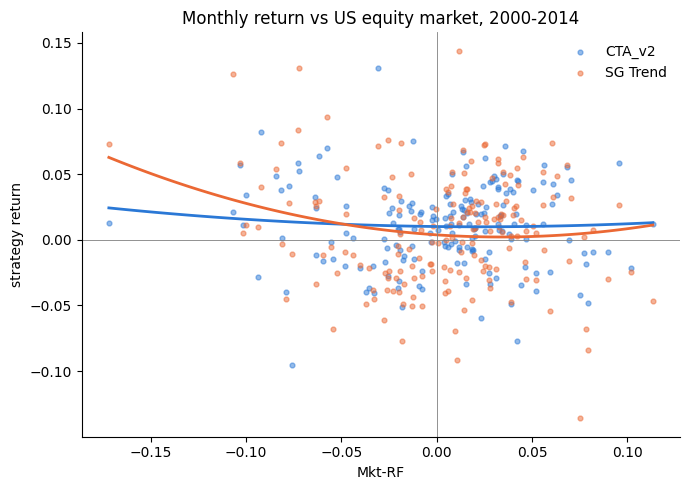

In [27]:
fig, ax = plt.subplots(figsize=(7, 5))
grid = np.linspace(mkt.min(), mkt.max(), 100)
for k, c in [("CTA_v2", "#2a78d6"), ("SG Trend", "#eb6834")]:
    ax.scatter(mkt, series[k], s=12, alpha=0.5, color=c, label=k)
    ax.plot(grid, np.polyval(np.polyfit(mkt, series[k], 2), grid), color=c, lw=2)
ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
ax.set(title="Monthly return vs US equity market, 2000-2014", xlabel="Mkt-RF", ylabel="strategy return")
ax.legend(frameon=False)
plt.tight_layout()

## 9. Look-ahead tests

`tests/test_lookahead.py` runs 15 checks. The main ones replace every return after month t with random numbers
and require the weights decided at t to stay exactly the same, for the monthly strategies, the daily risk model
and the continuity filter. Other tests check the position formulas and the Lecture 6 replication.

In [28]:
out = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", "tests"], cwd=ROOT, capture_output=True, text=True)
print(out.stdout[-600:])

...............                                                          [100%]
15 passed in 10.26s

